<a href="https://colab.research.google.com/github/DhaiHamoud/Fraud-Detection-in-the-Financial-Transaction-Market/blob/main/notebooks/04_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import gdown, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
gdown.download(id='11E44BQI86alA9DtSmEr3_yAiUvlzw8Sz', output='features.parquet', quiet=False)
df = pd.read_parquet('features.parquet')

Downloading...
From: https://drive.google.com/uc?id=11E44BQI86alA9DtSmEr3_yAiUvlzw8Sz
To: /content/features.parquet
100%|██████████| 47.1M/47.1M [00:00<00:00, 91.6MB/s]


## 1. Data Split and Baseline — Lana

In [2]:
# Time-based split: train = Jan-Sep 2019, validation = Oct-Dec 2019, test = 2020
train_part = (df['is_train'] == 1) & (df['month'] <= 9)
val_part = (df['is_train'] == 1) & (df['month'] >= 10)
test_part = df['is_train'] == 0

# Features (X) and target (y)
features = [c for c in df.columns if c not in ['is_fraud', 'is_train']]
X_train, y_train = df.loc[train_part, features], df.loc[train_part, 'is_fraud']
X_val, y_val = df.loc[val_part, features], df.loc[val_part, 'is_fraud']
X_test, y_test = df.loc[test_part, features], df.loc[test_part, 'is_fraud']

# Size and fraud rate of each part
for name, y in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f'{name}: {len(y):,} rows, {y.sum():,} fraud ({y.mean()*100:.2f}%)')
print('Number of features:', len(features))

Train: 644,611 rows, 3,786 fraud (0.59%)
Validation: 280,239 rows, 1,434 fraud (0.51%)
Test: 927,544 rows, 4,431 fraud (0.48%)
Number of features: 25


In [3]:
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, roc_auc_score

# Calculate all metrics from the fraud probabilities (threshold 0.5 by default)
def evaluate(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred),
            'f1': f1_score(y_true, y_pred),
            'pr_auc': average_precision_score(y_true, y_prob),
            'roc_auc': roc_auc_score(y_true, y_prob)}

# Validation results of every model are stored here
results = {}

In [4]:
from sklearn.dummy import DummyClassifier

# Baseline: always predicts the most common class (legitimate)
# # Minimum performance to beat: every model that comes next should perform better than this baseline
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
results['Baseline'] = evaluate(y_val, baseline.predict_proba(X_val)[:, 1])
pd.DataFrame(results).T.round(3)

,precision,recall,f1,pr_auc,roc_auc
Baseline,0.0,0.0,0.0,0.005,0.5


Notes:

* **Data Split:**
  * **Train (Jan-Sep 2019):** 644,611 rows, 3,786 fraud cases (0.59%).
  * **Validation (Oct-Dec 2019):** 280,239 rows, 1,434 fraud cases (0.51%).
  * **Test (2020):** 927,544 rows, 4,431 fraud cases (0.48%).
  * **Features:** The data has 25 features.
  * **Fraud rate:** Fraud is rare in all three parts, and its rate falls slightly over time.

* **Time-Based Validation:**
  * **Why late 2019:** The model will be used on future transactions, so we validate it on data that comes after its training period.
  * **Why not a random split:** The model could learn from later months and then predict earlier ones, making the results look better than they would be in real use.

* **Baseline Results:**
  * **Scores:** Precision = 0.0, Recall = 0.0, F1 = 0.0, PR-AUC = 0.005, and ROC-AUC = 0.5.
  * **Why F1 is 0:** The baseline labels every transaction as legitimate, so it catches none of the 1,434 fraud cases in validation. Precision and recall are both 0, so F1 is also 0.
  * **Why PR-AUC is about the fraud rate:** The baseline gives every transaction the same score, so it can't rank fraud above legitimate transactions. Its PR-AUC therefore equals the share of fraud in the data: 0.005, or about 0.51%.

* **Minimum Performance to Beat:**
  Any useful model should score well above the baseline's PR-AUC of 0.005 and ROC-AUC of 0.5, and it should catch actual fraud cases.

## 2. Logistic Regression — Turki

In [5]:
# importing the necessary libraries
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [6]:
# pipeline: scale the features, then logistic regression with balanced class weights to handle the class imbalance
logistic = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000))

# train the pipeline on the training data only (Jan-Sep 2019)
logistic.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [7]:
# evaluate on the validation data
results['Logistic Regression'] = evaluate(y_val,logistic.predict_proba(X_val)[:, 1])

# show the results table: one row per model, rounded to 3 decimals
pd.DataFrame(results).T.round(3)

,precision,recall,f1,pr_auc,roc_auc
Baseline,0.000,0.000,0.00,0.005,0.500
Logistic Regression,0.048,0.796,0.09,0.216,0.956


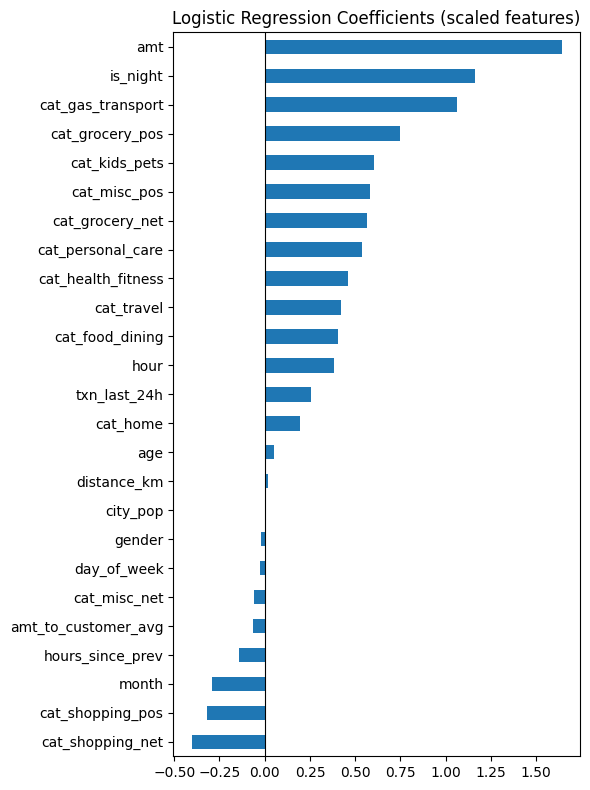

In [8]:
# coefficient of each feature, sorted: positive = increases fraud probability, negative = decreases it
coef = pd.Series(logistic[-1].coef_[0], index=features).sort_values()

# horizontal bar plot of the coefficients
coef.plot(kind='barh', figsize=(6, 8))
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Logistic Regression Coefficients (scaled features)')
plt.tight_layout()
plt.show()


- **Result vs baseline:** The baseline scored 0 on precision, recall, and F1, with PR-AUC of 0.005 and ROC-AUC of 0.5. Logistic Regression scored precision 0.048, recall 0.796, F1 0.09, PR-AUC 0.216, and ROC-AUC 0.956. It catches about 80% of fraud, and its PR-AUC is about 40 times higher than the baseline's.

- **Why recall is high and precision is very low:** `class_weight='balanced'` makes a missed fraud count much more than a mistake on a legitimate transaction, so the model flags many transactions as fraud at the default 0.5 threshold. This catches most fraud (high recall), but only about 5% of the alarms are real fraud (low precision). The threshold has not been tuned yet, and we will tune it in Task 4.

- **Top 3 positive features:** `amt`, `is_night`, and `cat_gas_transport`. `amt` and `is_night` agree with last week's results (fraud amounts were a lot higher, and fraud was more common at night). `cat_gas_transport` is consistent with last week's finding that fraud rates differ about 10 times between categories. One difference: `amt_to_customer_avg` was the strongest customer feature last week, but its coefficient here is close to zero, likely because it overlaps with `amt`.

## 3. Random Forest — Faisal

In [9]:
from sklearn.ensemble import RandomForestClassifier

# 100 trees with limited depth; balanced_subsample handles the rare fraud class
forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=20,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=42
)

# Train the model on the training set (takes ~1-2 minutes)
forest.fit(X_train, y_train)

# Evaluate on validation data and update results table
results['Random Forest'] = evaluate(y_val, forest.predict_proba(X_val)[:, 1])
pd.DataFrame(results).T.round(3)

,precision,recall,f1,pr_auc,roc_auc
Baseline,0.000,0.000,0.000,0.005,0.500
Logistic Regression,0.048,0.796,0.090,0.216,0.956
Random Forest,0.343,0.932,0.502,0.866,0.995


**Observations:**

* **Comparison (validation data):**
  * **vs Baseline:** Random Forest is far better on every metric (F1 0.502 vs 0.000, PR-AUC 0.866 vs 0.005).
  * **vs Logistic Regression:** PR-AUC rose from 0.216 to 0.866 (about 4 times higher). Recall rose from 0.796 to 0.932, so it catches 93% of fraud at the default 0.5 threshold. Precision rose from 0.048 to 0.343, so it gives far fewer false alarms.
  * **Most improved metric:** PR-AUC (+0.650). This means Random Forest ranks fraud above legitimate transactions much better than the linear model, at every threshold.

* **Meaning of the settings:**
  * `max_depth=12`: each tree can ask at most 12 questions from the top to the final decision.
  * `min_samples_leaf=20`: each final decision must be based on at least 20 transactions, so a tree cannot build a rule for a single unusual transaction.
  * **Why we set them:** Without limits, the trees grow very deep and memorize individual fraud cases. That makes training slow, the model file very large, and the model less reliable on new data. With limits, training takes about 2 minutes and the file stays small enough to upload.

* **Why scaling is not needed:** A tree splits one feature at a time using a cut-off value, such as "amt above 300". Scaling changes the numbers but not their order, so the splits stay the same. Logistic Regression multiplies each feature by a weight and adds them up, so a feature with large values like `amt` would dominate unless all features are scaled.

## 4. Comparison, Threshold, and Test — Rayan

In [10]:
# Comparison table of all models on the validation data
table = pd.DataFrame(results).T.round(3)
print(table)

# Pick the best model by PR-AUC on validation (the baseline is not a real model, so we drop it)
models = {'Logistic Regression': logistic, 'Random Forest': forest}
best_name = table.drop('Baseline')['pr_auc'].idxmax()
best_model = models[best_name]
print('Best model on validation (PR-AUC):', best_name)

                     precision  recall     f1  pr_auc  roc_auc
Baseline                 0.000   0.000  0.000   0.005    0.500
Logistic Regression      0.048   0.796  0.090   0.216    0.956
Random Forest            0.343   0.932  0.502   0.866    0.995
Best model on validation (PR-AUC): Random Forest


Best threshold: 0.840  Precision: 0.864  Recall: 0.783  F1: 0.822


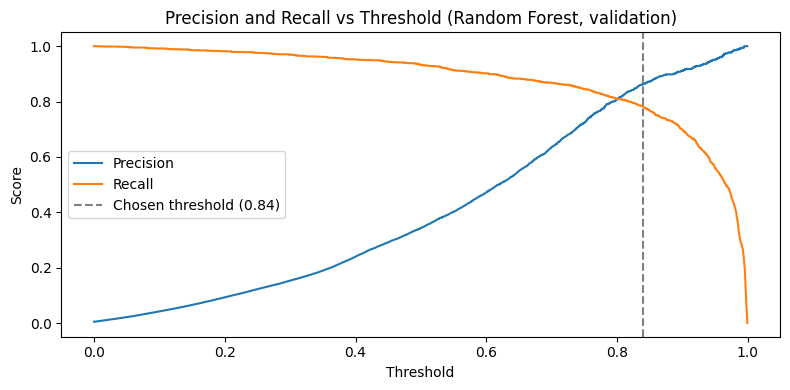

In [11]:
from sklearn.metrics import precision_recall_curve

# Precision and recall for every possible threshold (validation data)
val_prob = best_model.predict_proba(X_val)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, val_prob)
f1 = 2 * precision * recall / (precision + recall + 1e-9)

# Threshold with the highest F1
best_i = f1[:-1].argmax()
best_threshold = thresholds[best_i]
print(f'Best threshold: {best_threshold:.3f}  Precision: {precision[best_i]:.3f}  '
      f'Recall: {recall[best_i]:.3f}  F1: {f1[best_i]:.3f}')

# Plot precision and recall against the threshold
plt.figure(figsize=(8, 4))
plt.plot(thresholds, precision[:-1], label='Precision')
plt.plot(thresholds, recall[:-1], label='Recall')
plt.axvline(best_threshold, color='gray', linestyle='--', label=f'Chosen threshold ({best_threshold:.2f})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title(f'Precision and Recall vs Threshold ({best_name}, validation)')
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Alternative: highest threshold that still catches at least 80% of fraud
alt_threshold = thresholds[recall[:-1] >= 0.80].max()
print(f'Alternative threshold: {alt_threshold:.3f}')
print(pd.Series(evaluate(y_val, val_prob, alt_threshold)).round(3))

Alternative threshold: 0.819
precision    0.837
recall       0.801
f1           0.819
pr_auc       0.866
roc_auc      0.995
dtype: float64


**Threshold choice:** I picked 0.819 instead of 0.840. F1 is almost the same (0.819 vs 0.822), but 0.819 catches more fraud (80% vs 78%). In our project, missing a fraud is worse than a false alarm, so I went with the higher recall.

In [13]:
# Use the 80%-recall threshold (see the note above)
best_threshold = alt_threshold
print(f'Threshold used on the test data: {best_threshold:.3f}')

Threshold used on the test data: 0.819


In [14]:
# Final evaluation on 2020 (used once, with the model and threshold chosen above)
test_prob = best_model.predict_proba(X_test)[:, 1]
test_result = evaluate(y_test, test_prob, best_threshold)
pd.Series(test_result).round(3)

,0
precision,0.795
recall,0.780
f1,0.787
pr_auc,0.840
roc_auc,0.994


In [15]:
# Validation vs test, same model and same threshold, side by side
compare = pd.DataFrame({'Validation (Oct-Dec 2019)': evaluate(y_val, val_prob, best_threshold),
                        'Test (2020)': test_result}).round(3)
compare

,Validation (Oct-Dec 2019),Test (2020)
precision,0.837,0.795
recall,0.801,0.780
f1,0.819,0.787
pr_auc,0.866,0.840
roc_auc,0.995,0.994


**Notes:**

* **Which model is better:** Random Forest. On validation its PR-AUC is 0.866, while Logistic Regression got 0.216, so it is about 4 times better. We compared with PR-AUC because it does not depend on the 0.5 threshold.

* **Threshold:**
  * I used 0.819, so a transaction is flagged as fraud when its fraud probability is 0.819 or higher.
  * In simple words: on validation, the model catches about 80% of fraud, and about 84% of its alarms are real fraud.
  * The threshold is much higher than 0.5 because the class weights push the fraud probabilities up. At 0.5 the model gave too many false alarms (precision was only 0.343).

* **Test (2020) vs validation (late 2019):**
  * On 2020, the model catches 78% of fraud, and 79.5% of its alarms are real fraud (F1 0.787, PR-AUC 0.840).
  * All metrics dropped a little compared to validation (F1 0.819 → 0.787, PR-AUC 0.866 → 0.840), and recall went slightly below 80%.
  * So the model still works on 2020, but it is a bit weaker than on 2019. This is the first answer to our project question, and next week's monthly check will show if the drop gets bigger over time.

## 5. Error Analysis and Feature Importance — Abdulmohsen

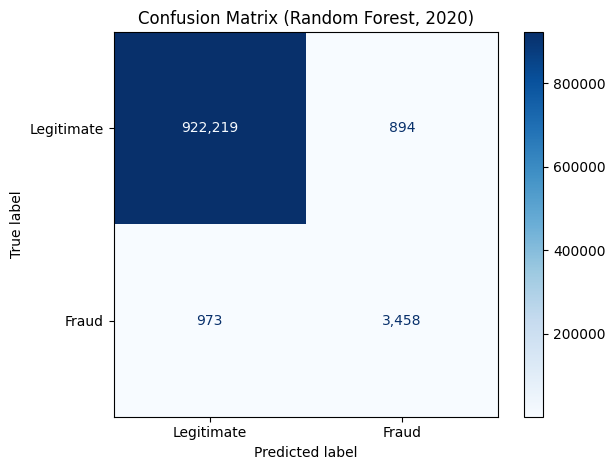

Correctly identified legitimate transactions (TN): 922,219
False alarms (FP): 894
Missed fraud (FN): 973
Detected fraud (TP): 3,458


In [16]:
# Analyze the existing test predictions using the chosen threshold
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

test_pred = (test_prob >= best_threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    labels=[0, 1],
    display_labels=['Legitimate', 'Fraud'],
    values_format=',',
    cmap='Blues'
)
plt.title(f'Confusion Matrix ({best_name}, 2020)')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(
    y_test, test_pred, labels=[0, 1]
).ravel()

print(f'Correctly identified legitimate transactions (TN): {tn:,}')
print(f'False alarms (FP): {fp:,}')
print(f'Missed fraud (FN): {fn:,}')
print(f'Detected fraud (TP): {tp:,}')

In [17]:
# Analyze fraud detection by category, amount, and transaction characteristics
cat_cols = [c for c in features if c.startswith('cat_')]

errors = X_test.copy()
errors['actual'] = y_test.to_numpy()
errors['predicted'] = test_pred

# Rebuild categories; entertainment is the reference category in the task template
errors['category'] = (
    errors[cat_cols].idxmax(axis=1).str.replace('cat_', '', regex=False)
)
errors.loc[
    errors[cat_cols].sum(axis=1) == 0, 'category'
] = 'entertainment'

fraud_rows = errors.loc[errors['actual'] == 1].copy()

# Show recall and the number of fraud cases in each category
category_summary = fraud_rows.groupby('category')['predicted'].agg(
    fraud_count='size',
    detected='sum',
    recall='mean'
)
category_summary['recall_pct'] = category_summary.pop('recall') * 100

print('Fraud detection by category:')
display(category_summary.sort_values('recall_pct').round(1))

# Include all non-negative amounts, including amounts above $30,000
fraud_rows['amount_range'] = pd.cut(
    fraud_rows['amt'],
    bins=[0, 50, 100, 300, 1000, np.inf],
    labels=['0–50', '50–100', '100–300', '300–1000', 'Above 1000'],
    include_lowest=True
)

amount_summary = fraud_rows.groupby(
    'amount_range', observed=True
)['predicted'].agg(
    fraud_count='size',
    detected='sum',
    recall='mean'
)
amount_summary['recall_pct'] = amount_summary.pop('recall') * 100

print('\nFraud detection by amount ($):')
display(amount_summary.round(1))

print('\nMedian values: missed (0) vs caught (1)')
display(
    fraud_rows.groupby('predicted')[
        ['amt', 'amt_to_customer_avg', 'hours_since_prev', 'is_night']
    ].median()
)

Fraud detection by category:


,fraud_count,detected,recall_pct
category,,,
food_dining,101,0,0.0
health_fitness,89,6,6.7
travel,70,5,7.1
personal_care,138,20,14.5
grocery_net,81,15,18.5
kids_pets,132,29,22.0
misc_pos,152,39,25.7
home,136,68,50.0
gas_transport,333,254,76.3



Fraud detection by amount ($):


,fraud_count,detected,recall_pct
amount_range,,,
0–50,926,335,36.2
50–100,28,0,0.0
100–300,566,373,65.9
300–1000,2362,2232,94.5
Above 1000,549,518,94.4



Median values: missed (0) vs caught (1)


,amt,amt_to_customer_avg,hours_since_prev,is_night
predicted,,,,
0,21.690,0.365921,2.917222,1.0
1,751.445,8.314292,1.133889,1.0


Top 10 features:


,0
amt,0.3495
amt_to_customer_avg,0.1995
is_night,0.1448
hour,0.1078
hours_since_prev,0.0519
cat_gas_transport,0.0223
age,0.0149
cat_grocery_pos,0.0136
txn_last_24h,0.0109
cat_shopping_net,0.0100


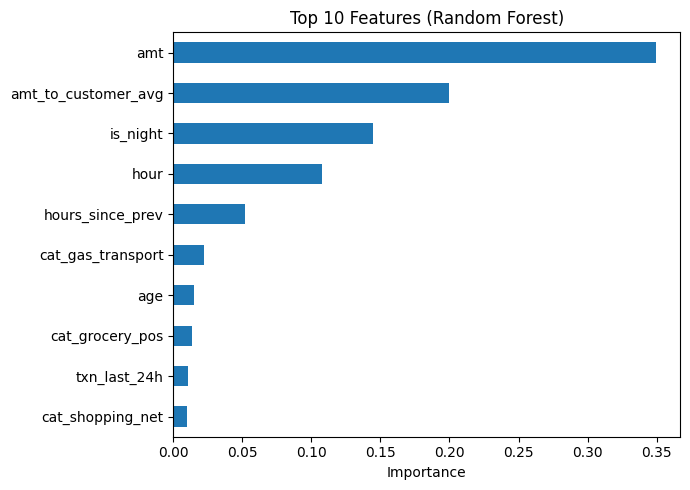

In [18]:
# Display the ten most important features in the trained Random Forest
importance = pd.Series(
    forest.feature_importances_,
    index=features
).sort_values(ascending=False)

print('Top 10 features:')
display(importance.head(10).round(4))

importance.head(10).sort_values().plot(
    kind='barh',
    figsize=(7, 5)
)
plt.title('Top 10 Features (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

**Observations:**

* **Confusion matrix:** The model detected 3,458 of 4,431 fraud transactions (78.0%) and missed 973. It also raised 894 false alarms and correctly classified 922,219 legitimate transactions.

* **Where the model struggles:** Small-amount fraud is a major weakness. Recall was only 36.2% for amounts up to $50, compared with about 94.5% for amounts above $300. None of the 28 fraud cases between $50 and $100 were detected, although this group is relatively small.

* **Differences by category:** Recall varied considerably. The model detected none of the 101 fraud cases in food_dining, compared with 96.1% in grocery_pos and 95.3% in shopping_net.

* **Missed vs detected fraud:** Missed fraud had a median amount of $21.69, compared with $751.45 for detected fraud. Its median amount-to-customer-average ratio was also lower (0.366 vs 8.314). This suggests that the model struggles with fraud involving small amounts that are not unusually large relative to the customer's average.

* **Top 3 features:**
  * `amt` (0.3495): transaction amount.
  * `amt_to_customer_avg` (0.1995): transaction amount relative to the customer's average.
  * `is_night` (0.1448): whether the transaction occurred at night.

  Together, these features account for about 69.4% of the Random Forest's total feature importance. These scores describe the model's reliance on the features; they do not show whether a feature increases or decreases a prediction.

* **Main takeaway:** At the chosen threshold, the model detects large-amount fraud much more reliably than small-amount fraud, and its performance differs substantially across transaction categories.

* **Comparison with last week's feature table:** The top three features agree with our earlier findings. The table reported that median fraud amounts were 8.3 times higher than legitimate amounts (`amt`), and the median amount-to-customer-average ratio was 5.03 for fraud versus 0.66 for legitimate transactions (`amt_to_customer_avg`). It also showed higher fraud rates at night (`is_night`). These findings are consistent with the Random Forest relying most heavily on these three features.